# HW2 : Uniform Convergence and the Limits of Learning
**Cours :** Apprentissage statistique et automatique  
**Prénom et nom :** Lorris SANNA  
**Master :** M2 IM - Université de Haute-Alsace  

---
**Objectif :** étudier par simulation la convergence uniforme (partie I), le No-Free-Lunch avec des cibles aléatoires (partie II) et l'effet d'un biais inductif avec des seuils (partie III).

**Paramètres choisis :** $\varepsilon = 0.1$, $\delta = 0.05$, $|H| \in \{5, 10, 50, 100, 500\}$, $m$ de $10$ à $600$ (partie I), $N = 100$ (parties II et III), 1000 à 5000 répétitions. Seulement `numpy` et `matplotlib`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

#paramètres choisis
EPS = 0.1 #précision epsilon
DELTA = 0.05 #confiance delta
TOL = 1e-9 #tolérance pour éviter les erreurs d'arrondi dans |LS - p| > eps
TAILLES_H = [5, 10, 50, 100, 500] #tailles de la classe H
M_GRID = np.arange(10, 601, 10) #valeurs de m
N_REP = 1000 #répétitions

# Partie I - Simuler la convergence uniforme
## 1. Le risque empirique comme variable aléatoire
On fixe $p = L_D(h) = 0.3$. Pour $m \in \{10, 50, 200, 1000\}$, on simule $E \sim \text{Binomial}(m, p)$ 5000 fois et on calcule $L_S(h) = E/m$.

   m | moyenne de LS | p | écart-type empirique | sqrt(p(1-p)/m)
  10 |        0.2983 | 0.3 |               0.1448 | 0.1449
  50 |        0.2981 | 0.3 |               0.0637 | 0.0648
 200 |        0.2998 | 0.3 |               0.0328 | 0.0324
1000 |        0.3001 | 0.3 |               0.0141 | 0.0145


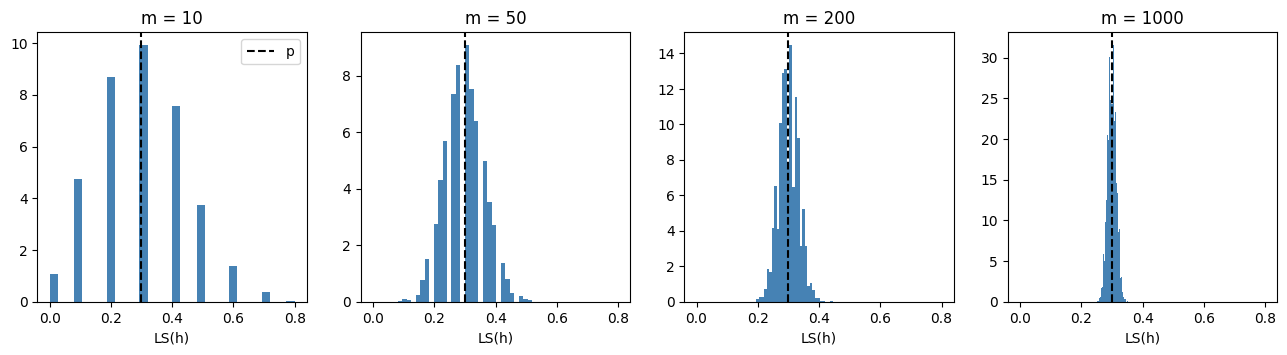

In [2]:
P_FIXE = 0.3
M_LISTE = [10, 50, 200, 1000]

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharex=True)
print("   m | moyenne de LS | p | écart-type empirique | sqrt(p(1-p)/m)")
for ax, m in zip(axes, M_LISTE):
    LS = np.random.binomial(m, P_FIXE, 5000) / m
    ax.hist(LS, bins=30, density=True, color="steelblue")
    ax.axvline(P_FIXE, color="k", linestyle="--", label="p")
    ax.set_title(f"m = {m}"); ax.set_xlabel("LS(h)")
    print(f"{m:4d} | {LS.mean():13.4f} | {P_FIXE} | {LS.std():20.4f} | {np.sqrt(P_FIXE*(1-P_FIXE)/m):.4f}")
axes[0].legend()
plt.show()

**Commentaire :**
- La moyenne de $L_S(h)$ est très proche de $p = 0.3$ pour tous les $m$ ($0.298$ à $0.300$).
- La dispersion diminue avec $m$ : l'écart-type vaut $0.145$, $0.064$, $0.033$, $0.014$ pour $m = 10, 50, 200, 1000$, ce qui correspond à $\sqrt{p(1-p)/m}$. Les histogrammes se resserrent donc autour de $p$ en $1/\sqrt{m}$.

## 2. Écart entre risque empirique et risque vrai
On estime $\Pr[|L_S(h) - L_D(h)| > \varepsilon]$ (5000 répétitions par $m$) pour $p \in \{0.1, 0.3, 0.5\}$, et on compare à la borne de Hoeffding $2e^{-2m\varepsilon^2}$.

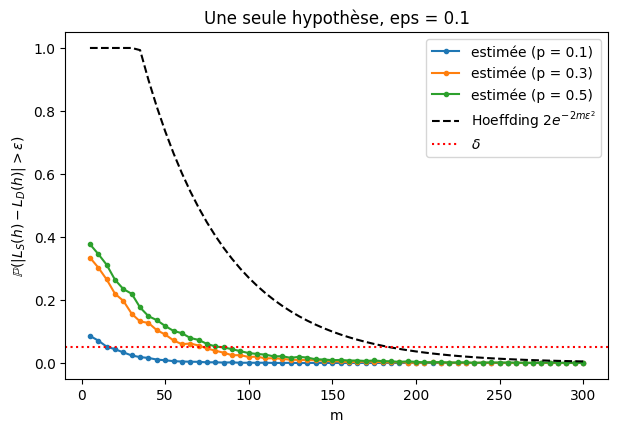

   m | p=0.1 | p=0.3 | p=0.5 | Hoeffding
  10 | 0.071 | 0.303 | 0.346 | 1.000
  50 | 0.009 | 0.090 | 0.117 | 0.736
 100 | 0.001 | 0.019 | 0.031 | 0.271
 200 | 0.000 | 0.001 | 0.004 | 0.037


In [3]:
P_LISTE = [0.1, 0.3, 0.5]
M_GRID2 = np.arange(5, 301, 5)

proba2 = {p: [np.mean(np.abs(np.random.binomial(m, p, 5000) / m - p) > EPS + TOL) for m in M_GRID2] for p in P_LISTE}
hoeffding = np.minimum(1, 2 * np.exp(-2 * M_GRID2 * EPS**2))

plt.figure(figsize=(7, 4.5))
for p in P_LISTE:
    plt.plot(M_GRID2, proba2[p], "o-", markersize=3, label=f"estimée (p = {p})")
plt.plot(M_GRID2, hoeffding, "k--", label=r"Hoeffding $2e^{-2m\varepsilon^2}$")
plt.axhline(DELTA, color="red", linestyle=":", label=r"$\delta$")
plt.xlabel("m"); plt.ylabel(r"$\mathbb{P}(|L_S(h) - L_D(h)| > \varepsilon)$")
plt.title(f"Une seule hypothèse, eps = {EPS}")
plt.legend(); plt.show()

print("   m | p=0.1 | p=0.3 | p=0.5 | Hoeffding")
for m in [10, 50, 100, 200]:
    i = list(M_GRID2).index(m)
    print(f"{m:4d} | {proba2[0.1][i]:.3f} | {proba2[0.3][i]:.3f} | {proba2[0.5][i]:.3f} | {hoeffding[i]:.3f}")

**Commentaire :**
- La probabilité estimée est toujours sous la borne de Hoeffding, mais la borne est **conservative** : à $m = 100$ et $p = 0.5$ on a $0.031$ contre $0.271$, et à $m = 200$ on a $0.004$ contre $0.037$ (environ 10 fois moins).
- La borne vaut $1$ tant que $m \lesssim 35$, donc elle ne dit rien pour les petits $m$.
- Elle ne dépend pas de $p$, alors que la vraie probabilité si : $p = 0.5$ (variance maximale) est le cas le plus difficile ($0.031$ contre $0.001$ pour $p = 0.1$ à $m = 100$).

## 3. Convergence uniforme
On prend $|H| = K$ hypothèses avec des risques $p_j$ répartis régulièrement dans $[0.05, 0.5]$. Pour chaque échantillon on simule les $K$ risques empiriques et on calcule $\Delta_S = \max_h |L_S(h) - L_D(h)|$, puis on estime $\Pr[\Delta_S > \varepsilon]$. On le fait directement pour toutes les tailles de $|H|$ (ça sert aussi aux questions 4 et 5). Ici $K = 50$ et on compare à $2|H|e^{-2m\varepsilon^2}$.

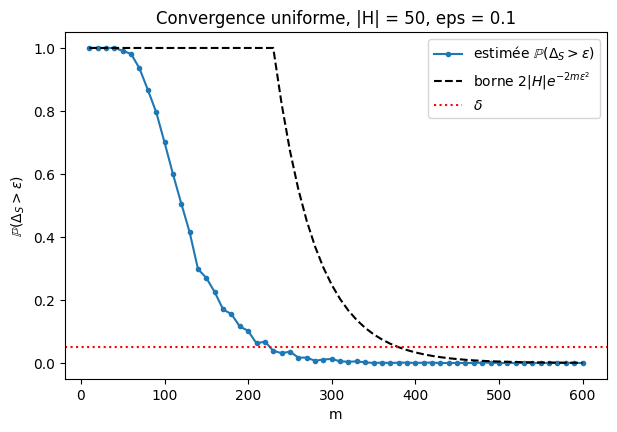

   m | estimée | borne
  50 |   0.991 | 1.000
 100 |   0.700 | 1.000
 150 |   0.270 | 1.000
 200 |   0.102 | 1.000
 300 |   0.013 | 0.248
 400 |   0.000 | 0.034


In [4]:
def proba_delta(K):
    #Pr[Delta_S > eps] pour chaque m, avec K hypothèses de vrais risques p_j
    p = np.linspace(0.05, 0.5, K)
    res = []
    for m in M_GRID:
        LS = np.random.binomial(m, p[None, :], size=(N_REP, K)) / m #risques empiriques
        delta_S = np.max(np.abs(LS - p[None, :]), axis=1)
        res.append(np.mean(delta_S > EPS + TOL))
    return np.array(res)

def borne_unif(K, m):
    return np.minimum(1, 2 * K * np.exp(-2 * m * EPS**2))

proba_H = {K: proba_delta(K) for K in TAILLES_H}

K = 50
plt.figure(figsize=(7, 4.5))
plt.plot(M_GRID, proba_H[K], "o-", markersize=3, label=r"estimée $\mathbb{P}(\Delta_S > \varepsilon)$")
plt.plot(M_GRID, borne_unif(K, M_GRID), "k--", label=r"borne $2|H|e^{-2m\varepsilon^2}$")
plt.axhline(DELTA, color="red", linestyle=":", label=r"$\delta$")
plt.xlabel("m"); plt.ylabel(r"$\mathbb{P}(\Delta_S > \varepsilon)$")
plt.title(f"Convergence uniforme, |H| = {K}, eps = {EPS}")
plt.legend(); plt.show()

print("   m | estimée | borne")
for m in [50, 100, 150, 200, 300, 400]:
    i = list(M_GRID).index(m)
    print(f"{m:4d} | {proba_H[K][i]:7.3f} | {borne_unif(K, m):.3f}")

**Commentaire :**
- Pour $|H| = 50$, la borne vaut $1$ jusqu'à $m \approx 230$, alors que la probabilité simulée est déjà de $0.27$ à $m = 150$ et $0.10$ à $m = 200$. À $m = 300$ on a $0.013$ contre une borne de $0.248$.
- Il faut contrôler les $50$ hypothèses en même temps, donc $\Pr[\Delta_S > \varepsilon]$ est beaucoup plus grande que pour une seule hypothèse (à $m = 100$ : $0.70$ contre $0.02$ à $0.03$).
- La borne est encore plus conservative qu'avant, car l'inégalité de l'union suppose que les événements sont disjoints.

## 4. Effet de la taille de la classe $|H|$
On trace $\Pr[\Delta_S > \varepsilon]$ en fonction de $m$ pour $|H| \in \{5, 10, 50, 100, 500\}$ (traits pleins = simulation, pointillés = borne).

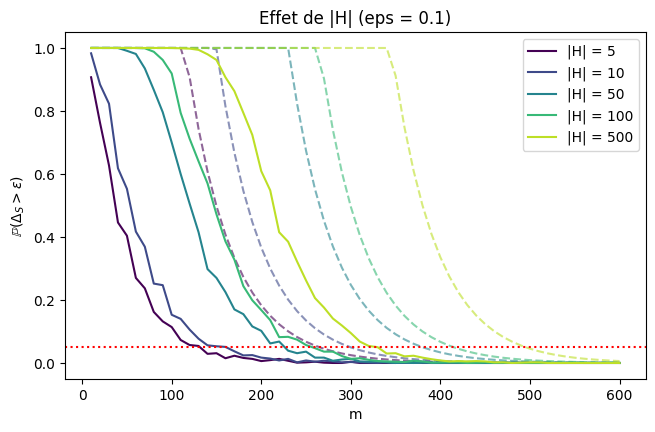

   m |  |H|=  5 | |H|= 10 | |H|= 50 | |H|=100 | |H|=500
  50 |    0.404 |   0.553 |   0.991 |   1.000 |   1.000
 100 |    0.114 |   0.153 |   0.700 |   0.919 |   1.000
 150 |    0.031 |   0.053 |   0.270 |   0.472 |   0.962
 200 |    0.006 |   0.017 |   0.102 |   0.168 |   0.609
 300 |    0.004 |   0.003 |   0.013 |   0.013 |   0.095


In [5]:
couleurs = plt.cm.viridis(np.linspace(0, 0.9, len(TAILLES_H)))
plt.figure(figsize=(7.5, 4.5))
for K, c in zip(TAILLES_H, couleurs):
    plt.plot(M_GRID, proba_H[K], "-", color=c, label=f"|H| = {K}")
    plt.plot(M_GRID, borne_unif(K, M_GRID), "--", color=c, alpha=0.6)
plt.axhline(DELTA, color="red", linestyle=":")
plt.xlabel("m"); plt.ylabel(r"$\mathbb{P}(\Delta_S > \varepsilon)$")
plt.title(f"Effet de |H| (eps = {EPS})")
plt.legend(); plt.show()

print("   m |  " + " | ".join(f"|H|={K:3d}" for K in TAILLES_H))
for m in [50, 100, 150, 200, 300]:
    i = list(M_GRID).index(m)
    print(f"{m:4d} |  " + " | ".join(f"{proba_H[K][i]:7.3f}" for K in TAILLES_H))

**Commentaire :**
- Plus $|H|$ est grand, plus la courbe est décalée vers la droite : à $m = 200$ on a $0.006$, $0.017$, $0.102$, $0.168$, $0.609$ pour $|H| = 5, 10, 50, 100, 500$. Il y a plus d'hypothèses qui peuvent dévier par malchance, et $\Delta_S$ est le maximum de toutes ces déviations.
- Une classe plus grande demande donc plus de données, mais pas proportionnellement : $|H|$ est multiplié par $100$ et il faut seulement quelques centaines d'exemples de plus. C'est la dépendance en $\log|H|$ de la borne $m \ge \log(2|H|/\delta)/(2\varepsilon^2)$.

## 5. Complexité d'échantillon expérimentale
Avec $\varepsilon = 0.1$ et $\delta = 0.05$, on cherche le plus petit $m$ de la grille tel que $\Pr[\Delta_S > \varepsilon] \le \delta$, et on le compare à $m \ge \dfrac{\log(2|H|/\delta)}{2\varepsilon^2}$.

|H| | m expérimental | m théorique
  5 |            140 | 265
 10 |            170 | 300
 50 |            230 | 381
100 |            260 | 415
500 |            330 | 496


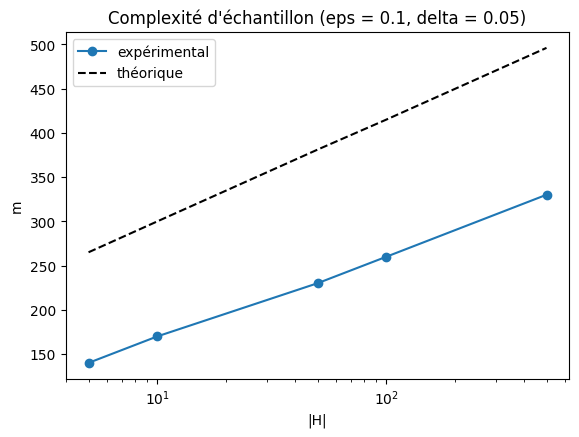

In [6]:
print("|H| | m expérimental | m théorique")
m_exp, m_theo = [], []
for K in TAILLES_H:
    me = int(M_GRID[np.where(proba_H[K] <= DELTA)[0][0]]) #premier m qui passe sous delta
    mt = int(np.ceil(np.log(2 * K / DELTA) / (2 * EPS**2)))
    m_exp.append(me); m_theo.append(mt)
    print(f"{K:3d} | {me:14d} | {mt}")

plt.figure(figsize=(6.5, 4.5))
plt.plot(TAILLES_H, m_exp, "o-", label="expérimental")
plt.plot(TAILLES_H, m_theo, "k--", label="théorique")
plt.xscale("log"); plt.xlabel("|H|"); plt.ylabel("m")
plt.title(f"Complexité d'échantillon (eps = {EPS}, delta = {DELTA})")
plt.legend(); plt.show()

**Commentaire :**
- Le $m$ expérimental est toujours plus petit que le $m$ théorique ($140$ contre $265$ pour $|H| = 5$, $260$ contre $415$ pour $|H| = 100$, $330$ contre $496$ pour $|H| = 500$). La borne est une condition **suffisante** : elle garantit $\Pr[\Delta_S > \varepsilon] \le \delta$ mais pas forcément le plus petit $m$ possible, parce qu'elle utilise l'inégalité de l'union et Hoeffding (qui ne tient pas compte de la variance réelle).
- La croissance en $\log|H|$ se voit : quand $|H|$ est multiplié par $10$, le $m$ expérimental augmente d'environ $90$ à $100$ ($140 \to 230$, $170 \to 260$, $230 \to 330$), la théorie prévoit $\ln(10)/(2\varepsilon^2) \approx 115$.
- Les valeurs expérimentales sont données à la précision de la grille (pas de $10$) et de Monte-Carlo.

# Partie II - Simuler le No-Free-Lunch
Domaine $\mathcal{X} = \{1, \dots, N\}$ avec la loi uniforme. À chaque répétition on tire une nouvelle cible $f(x) \sim \text{Bernoulli}(1/2)$ pour chaque $x$, puis un échantillon de $m$ points. Le learner mémorise : il prédit le label observé si $x$ a été vu, et une règle par défaut sinon (au départ : $0$). Les labels n'ont pas de bruit, donc le label observé est $f(x)$.

In [7]:
N_REP_NFL = 2000
M_LISTE2 = [1, 2, 5, 10, 20, 50, 100, 200, 500]

def une_repetition(N, m, regle="zero"):
    #retourne (fraction de points non vus, vrai risque de A(S))
    f = np.random.randint(0, 2, N) #cible aléatoire
    S = np.random.randint(0, N, m) #échantillon
    vu = np.zeros(N, dtype=bool)
    vu[S] = True
    if regle == "zero":
        defaut = np.zeros(N, dtype=int)
    elif regle == "un":
        defaut = np.ones(N, dtype=int)
    else: #Bernoulli(1/2)
        defaut = np.random.randint(0, 2, N)
    pred = np.where(vu, f, defaut)
    return np.mean(~vu), np.mean(pred != f)

def simuler_nfl(N, m, regle="zero"):
    res = np.array([une_repetition(N, m, regle) for _ in range(N_REP_NFL)])
    return res[:, 0].mean(), res[:, 1].mean()

## 6. Points vus et non vus
On estime la fraction moyenne de points jamais observés pour $N \in \{20, 50, 100, 200\}$ et on la compare à $(1 - 1/N)^m$.

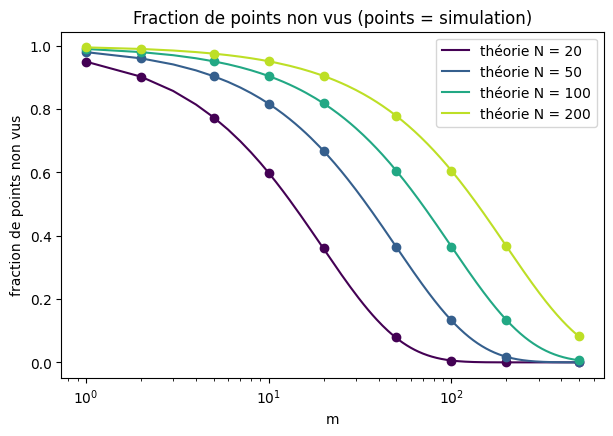

N = 100 :   m | simulée | théorique
           1 |  0.9900 | 0.9900
           2 |  0.9801 | 0.9801
           5 |  0.9511 | 0.9510
          10 |  0.9043 | 0.9044
          20 |  0.8178 | 0.8179
          50 |  0.6050 | 0.6050
         100 |  0.3656 | 0.3660
         200 |  0.1348 | 0.1340
         500 |  0.0062 | 0.0066
écart max sur tous les N et m : 0.0039


In [8]:
NS = [20, 50, 100, 200]
frac_exp = {N: [simuler_nfl(N, m)[0] for m in M_LISTE2] for N in NS}
m_fin = np.arange(1, 501)

plt.figure(figsize=(7, 4.5))
for N, c in zip(NS, plt.cm.viridis(np.linspace(0, 0.9, len(NS)))):
    plt.plot(m_fin, (1 - 1 / N) ** m_fin, "-", color=c, label=f"théorie N = {N}")
    plt.plot(M_LISTE2, frac_exp[N], "o", color=c)
plt.xscale("log"); plt.xlabel("m"); plt.ylabel("fraction de points non vus")
plt.title("Fraction de points non vus (points = simulation)")
plt.legend(); plt.show()

print("N = 100 :   m | simulée | théorique")
for m, fe in zip(M_LISTE2, frac_exp[100]):
    print(f"        {m:4d} | {fe:7.4f} | {(1 - 1/100) ** m:.4f}")
print("écart max sur tous les N et m :", max(abs(frac_exp[N][i] - (1 - 1/N) ** m) for N in NS for i, m in enumerate(M_LISTE2)).round(4))

**Commentaire :** la simulation colle à $(1 - 1/N)^m$ pour tous les $N$ et $m$ (écart maximal $0.004$). Par exemple pour $N = 100$ : $0.605$ à $m = 50$, $0.366$ à $m = 100$ (environ $e^{-1}$), $0.006$ à $m = 500$.

C'est aussi la fraction espérée car, par linéarité, $\mathbb{E}\left[\frac1N\sum_x \mathbf{1}[x \text{ non vu}]\right] = \frac1N \sum_x \Pr[x \text{ non vu}] = (1 - 1/N)^m$ : chacun des $m$ tirages évite $x$ avec probabilité $1 - 1/N$.

## 7. Erreur sur les points non vus
**Dérivation :** sur un point vu l'erreur est $0$. Sur un point non vu la prédiction est $0$ et $f(x) \sim \text{Bernoulli}(1/2)$ est indépendant de l'échantillon, donc l'erreur vaut $1/2$ en probabilité. Par linéarité :
$$\mathbb{E}[L_D(A(S))] = \frac{1}{N}\sum_x \tfrac12 \Pr[x \text{ non vu}] = \frac12\left(1 - \frac1N\right)^m.$$

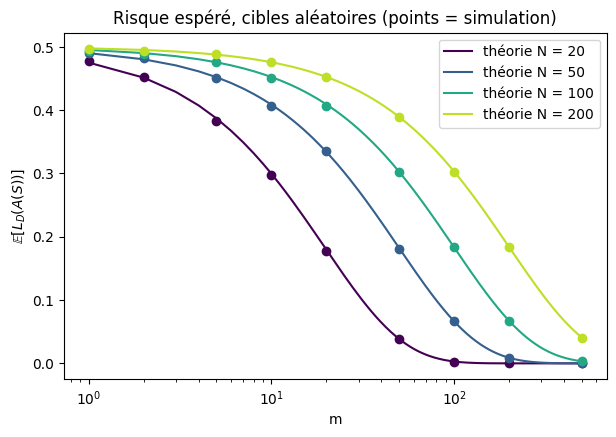

N = 100 :   m | simulé | théorique
           1 | 0.4930 | 0.4950
           2 | 0.4887 | 0.4900
           5 | 0.4758 | 0.4755
          10 | 0.4503 | 0.4522
          20 | 0.4068 | 0.4090
          50 | 0.3029 | 0.3025
         100 | 0.1837 | 0.1830
         200 | 0.0665 | 0.0670
         500 | 0.0033 | 0.0033
écart max sur tous les N et m : 0.0037


In [9]:
risque_exp = {N: [simuler_nfl(N, m)[1] for m in M_LISTE2] for N in NS}

plt.figure(figsize=(7, 4.5))
for N, c in zip(NS, plt.cm.viridis(np.linspace(0, 0.9, len(NS)))):
    plt.plot(m_fin, 0.5 * (1 - 1 / N) ** m_fin, "-", color=c, label=f"théorie N = {N}")
    plt.plot(M_LISTE2, risque_exp[N], "o", color=c)
plt.xscale("log"); plt.xlabel("m"); plt.ylabel(r"$\mathbb{E}[L_D(A(S))]$")
plt.title("Risque espéré, cibles aléatoires (points = simulation)")
plt.legend(); plt.show()

print("N = 100 :   m | simulé | théorique")
for m, r in zip(M_LISTE2, risque_exp[100]):
    print(f"        {m:4d} | {r:.4f} | {0.5 * (1 - 1/100) ** m:.4f}")
print("écart max sur tous les N et m :", max(abs(risque_exp[N][i] - 0.5 * (1 - 1/N) ** m) for N in NS for i, m in enumerate(M_LISTE2)).round(4))

**Commentaire :** les points simulés sont sur la courbe $\frac12(1 - 1/N)^m$ (écart maximal $0.004$). Pour $N = 100$ : $0.493$ à $m = 1$, $0.303$ à $m = 50$, $0.184$ à $m = 100$, $0.067$ à $m = 200$.

Le learner ne fait que mémoriser : sur les points non vus il se trompe une fois sur deux, et le risque baisse seulement parce que la fraction de points non vus baisse. Il faut donc $m$ grand devant $N$ pour avoir un petit risque.

## 8. Changer la prédiction sur les points non vus
On compare trois règles pour les points non vus : toujours $0$, toujours $1$, ou Bernoulli($1/2$). Cibles complètement aléatoires, $N = 100$.

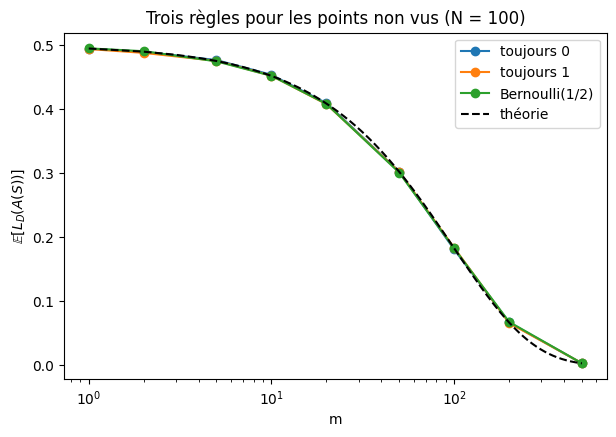

   m | toujours 0 | toujours 1 | Bernoulli | théorie
   1 |     0.4946 |     0.4942 |    0.4952 | 0.4950
   2 |     0.4900 |     0.4882 |    0.4908 | 0.4900
   5 |     0.4769 |     0.4757 |    0.4749 | 0.4755
  10 |     0.4539 |     0.4525 |    0.4523 | 0.4522
  20 |     0.4096 |     0.4081 |    0.4084 | 0.4090
  50 |     0.3028 |     0.3026 |    0.3012 | 0.3025
 100 |     0.1811 |     0.1837 |    0.1827 | 0.1830
 200 |     0.0671 |     0.0662 |    0.0679 | 0.0670
 500 |     0.0032 |     0.0035 |    0.0034 | 0.0033


In [10]:
N8 = 100
regles = {"zero": "toujours 0", "un": "toujours 1", "aleatoire": "Bernoulli(1/2)"}
risque_regles = {r: [simuler_nfl(N8, m, r)[1] for m in M_LISTE2] for r in regles}

plt.figure(figsize=(7, 4.5))
for r, nom in regles.items():
    plt.plot(M_LISTE2, risque_regles[r], "o-", label=nom)
plt.plot(m_fin, 0.5 * (1 - 1 / N8) ** m_fin, "k--", label="théorie")
plt.xscale("log"); plt.xlabel("m"); plt.ylabel(r"$\mathbb{E}[L_D(A(S))]$")
plt.title(f"Trois règles pour les points non vus (N = {N8})")
plt.legend(); plt.show()

print("   m | toujours 0 | toujours 1 | Bernoulli | théorie")
for i, m in enumerate(M_LISTE2):
    print(f"{m:4d} | {risque_regles['zero'][i]:10.4f} | {risque_regles['un'][i]:10.4f} | {risque_regles['aleatoire'][i]:9.4f} | {0.5 * (1 - 1/N8) ** m:.4f}")

**Commentaire :** les trois règles donnent le même risque, égal à $\frac12(1-1/N)^m$ (à $m = 50$ : $0.3028$, $0.3026$, $0.3012$ pour une théorie de $0.3025$). Les différences sont de l'ordre de l'erreur de Monte-Carlo, donc aucune règle ne fait mieux que les autres.

**Lien avec le No-Free-Lunch :** quand la cible est complètement aléatoire, les labels des points non vus sont indépendants de l'échantillon et valent $0$ ou $1$ avec probabilité $1/2$, donc toute prédiction se trompe une fois sur deux. En moyenne sur toutes les cibles, aucun learner n'est meilleur qu'un autre.

# Partie III - Introduire de la connaissance préalable
Même domaine, mais la cible est un seuil $f_\theta(x) = \mathbf{1}[x > \theta]$ avec $\theta$ tiré uniformément dans $\{1, \dots, N-1\}$. Le learner utilise ERM sur $H = \{h_t : t \in \{1, \dots, N-1\}\}$.

## 9. Apprendre avec un biais inductif adapté
**ERM :** il n'y a que $N - 1$ seuils, on calcule l'erreur empirique de chacun et on garde le meilleur (en cas d'égalité, le plus petit $t$). Le vrai risque sur tout le domaine vaut $L_D(h_t) = |t - \theta|/N$.

In [11]:
def erm_seuil_discret(X, y, N):
    ts = np.arange(1, N) #seuils candidats
    err = np.mean((X[None, :] > ts[:, None]) != y[None, :], axis=1) #erreur empirique de chaque seuil
    return ts[np.argmin(err)]

def repetition_seuil(N, m):
    theta = np.random.randint(1, N) #cible seuil
    X = np.random.randint(1, N + 1, m)
    y = (X > theta).astype(int)
    t = erm_seuil_discret(X, y, N)
    xs = np.arange(1, N + 1)
    return np.mean((xs > t) != (xs > theta)) #vrai risque sur tout le domaine

N9 = 100
risque_seuil = [np.mean([repetition_seuil(N9, m) for _ in range(N_REP_NFL)]) for m in M_LISTE2]
risque_alea = risque_exp[N9] #partie II

print(f"N = {N9} :   m | seuils + ERM | cibles aléatoires")
for m, a, b in zip(M_LISTE2, risque_seuil, risque_alea):
    print(f"        {m:4d} | {a:12.4f} | {b:.4f}")

N = 100 :   m | seuils + ERM | cibles aléatoires
           1 |       0.3270 | 0.4930
           2 |       0.2435 | 0.4887
           5 |       0.1395 | 0.4758
          10 |       0.0784 | 0.4503
          20 |       0.0419 | 0.4068
          50 |       0.0148 | 0.3029
         100 |       0.0055 | 0.1837
         200 |       0.0015 | 0.0665
         500 |       0.0000 | 0.0033


**Commentaire :** avec les seuils et l'ERM, le risque diminue beaucoup plus vite que pour les cibles aléatoires :
- $m = 10$ : $0.078$ contre $0.450$ ;
- $m = 50$ : $0.0148$ contre $0.303$ ;
- $m = 100$ : $0.0055$ contre $0.184$ (environ 33 fois moins).

Avec seulement $10$ exemples sur $100$ points, le learner généralise déjà bien, alors que dans la partie II il est encore presque au hasard.

## 10. Cibles aléatoires vs cibles structurées

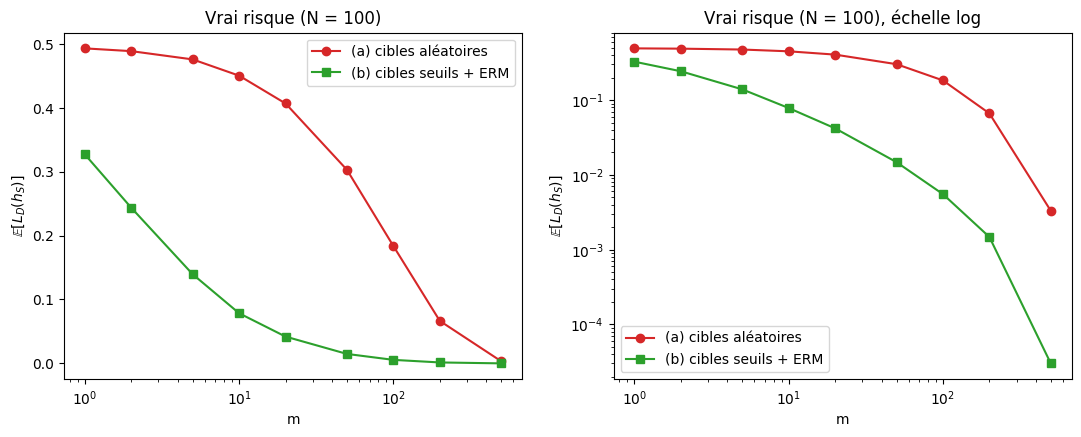

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, log_y in zip(axes, [False, True]):
    ax.plot(M_LISTE2, risque_alea, "o-", color="tab:red", label="(a) cibles aléatoires")
    ax.plot(M_LISTE2, risque_seuil, "s-", color="tab:green", label="(b) cibles seuils + ERM")
    ax.set_xscale("log"); ax.set_xlabel("m"); ax.set_ylabel(r"$\mathbb{E}[L_D(h_S)]$")
    if log_y: ax.set_yscale("log")
    ax.set_title(f"Vrai risque (N = {N9})" + (", échelle log" if log_y else ""))
    ax.legend()
plt.show()

**Commentaire :** la courbe (b) est sous la courbe (a) pour tous les $m$ (surtout visible en échelle log).

Le learner généralise bien dans le second cas parce qu'on suppose que la cible est un seuil. Les labels des points non vus sont alors liés à ceux des points vus : si on a vu un $0$ en $x_1$ et un $1$ en $x_2$, le seuil est entre les deux et seuls les points entre $x_1$ et $x_2$ restent incertains. Dans la partie II les points non vus étaient indépendants de l'échantillon. De plus $H$ ne contient que $N - 1 = 99$ fonctions (contre $2^N$ pour toutes les fonctions), donc $\log|H|$ est petit et peu d'exemples suffisent, comme en partie I. Cette garantie suppose que la cible est bien dans la famille des seuils.

## 11. Conclusion

- **Concentration :** $L_S(h)$ est une moyenne de $m$ variables de Bernoulli, son écart-type vaut $\sqrt{p(1-p)/m}$ et diminue donc avec $m$ ($0.145$ à $0.014$ de $m = 10$ à $m = 1000$).
- **Contrôle simultané :** l'ERM choisit $h$ en fonction de l'échantillon, donc il faut que $L_S(h)$ soit proche de $L_D(h)$ pour toutes les hypothèses en même temps, c'est-à-dire que $\Delta_S$ soit petit.
- **Effet de $|H|$ :** plus $|H|$ est grand, plus $\Delta_S$ (un maximum) est grand, mais le $m$ nécessaire ne croît qu'en $\log|H|$ (environ $+90$ à $100$ exemples par facteur $10$).
- **Bornes conservatives :** l'inégalité de l'union et Hoeffding sont des pires cas ($m$ théorique de $415$ contre $260$ expérimentalement pour $|H| = 100$) : c'est une garantie suffisante, pas le minimum.
- **Cibles aléatoires et No-Free-Lunch :** les labels des points non vus sont des Bernoulli($1/2$) indépendants de l'échantillon, donc aucune règle ne fait mieux que $1/2$ sur eux. Le risque $\frac12(1-1/N)^m$ ne baisse que parce qu'on voit plus de points. Un learner ne peut pas deviner des labels arbitraires non vus à partir de l'échantillon seul.
- **Biais inductif :** supposer que la cible est un seuil et prendre $H$ = les seuils ($99$ fonctions) relie les labels de points différents. Le risque à $m = 100$ passe de $0.184$ à $0.0055$. Ça ne marche que si la cible est bien dans la classe.